In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc

In [2]:
#X1, ..., Xn ∼ R[0, θ].

In [36]:
#(a) Построить гистограммы для X(n) при разных n и сравнить с нормальной плотностью (с та-
#кими же математическим ожиданием и дисперсией, как у X(n)).

In [2]:
m = 1000
tetta = 8
stat = [0]*m
est = [0]*m
numbers = [10,100,200,500,1000]

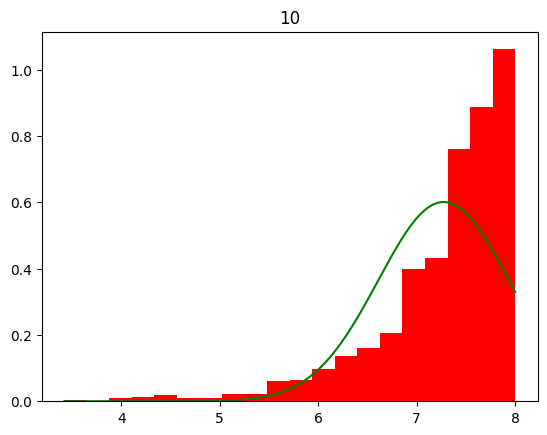

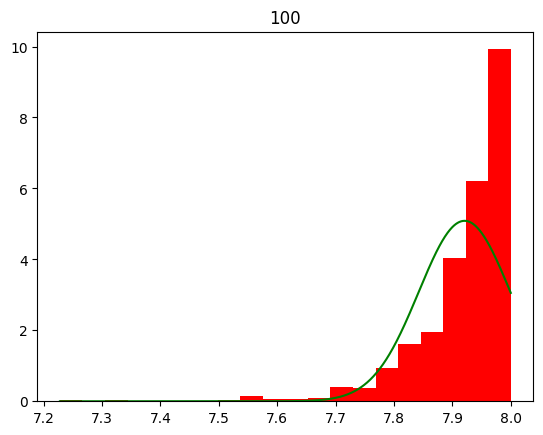

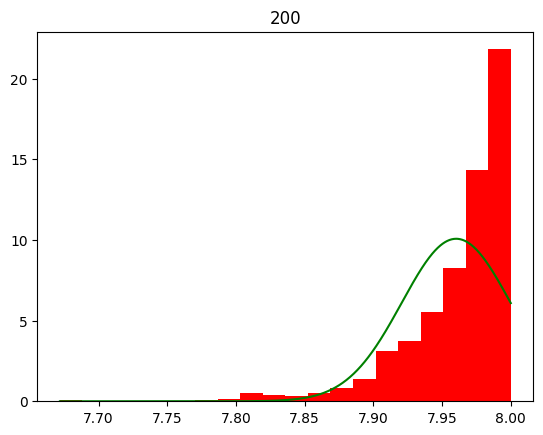

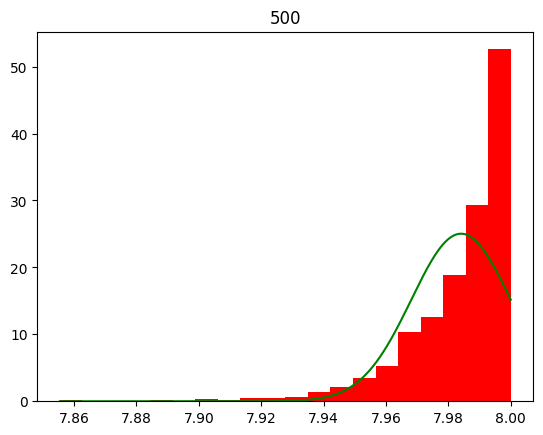

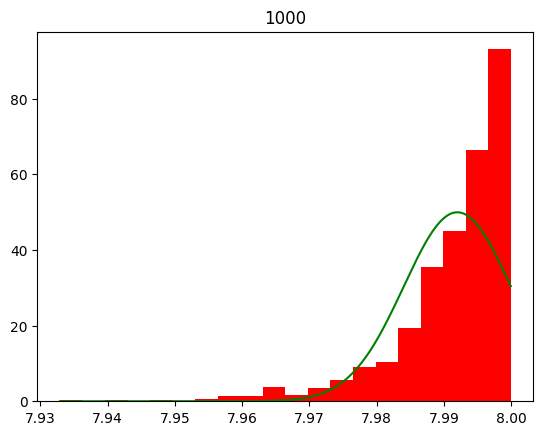

In [6]:
for n in numbers:
    for j in range(m):
        x = np.random.uniform(0, tetta, size = n)
        stat[j] = np.max(x)
        est[j] = n*(tetta - stat[j])
    plt.hist(stat, density = True, color = "red", bins = 20)
    x = np.linspace(np.min(stat), np.max(stat), 1000)
    plt.plot(x, sc.stats.norm.pdf(x, loc = ( n/(n+1) )*tetta, scale = np.sqrt(n / (n+2))*tetta/(n+1)), color = "green")
    plt.title(n)
    plt.show()

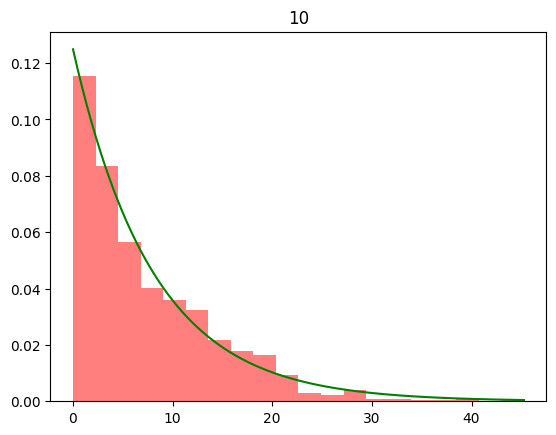

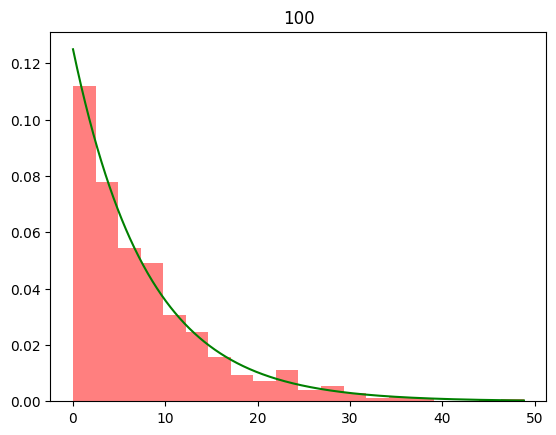

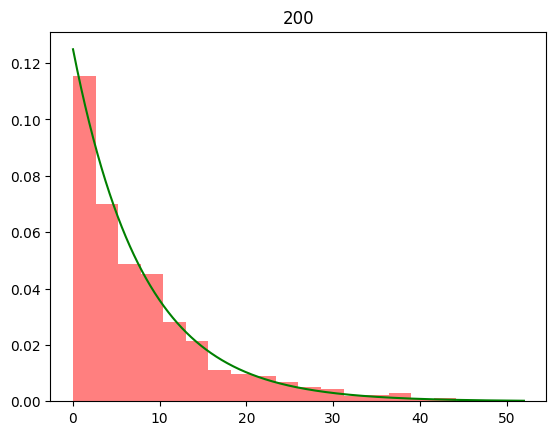

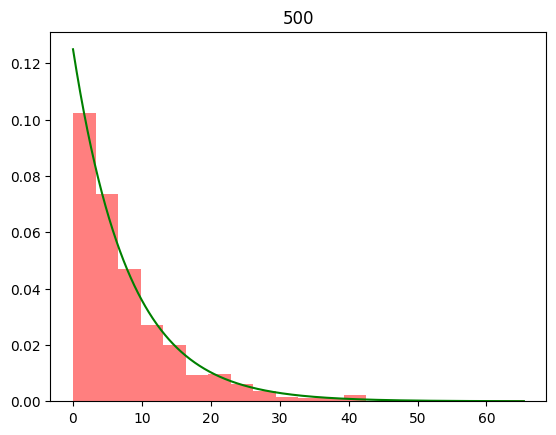

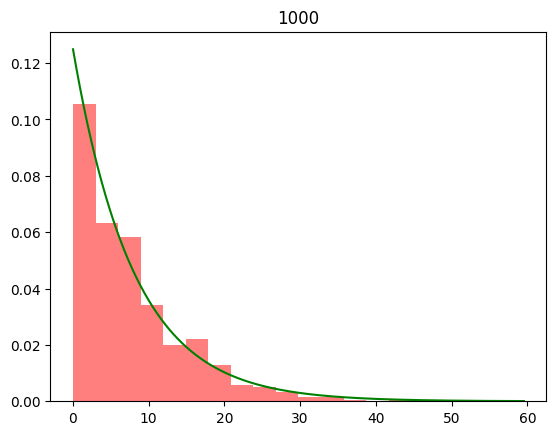

In [9]:
#(b) Построить гистограммы для n(θ−X(n)) при разных n и сравнить с плотностью распределения
#exp(1).

est = [0]*m
for n in numbers:
    for j in range(m):
        x = np.random.uniform(0, tetta, size = n)
        est[j] = n*(tetta - np.max(x))
    plt.hist(est, density = True, color = "red", bins = 20, alpha = 0.5)
    x = np.linspace(np.min(est), np.max(est), 1000)
    plt.plot(x, sc.stats.expon.pdf(x, loc = 0, scale = tetta), color = "green")
    plt.title(n)
    plt.show()

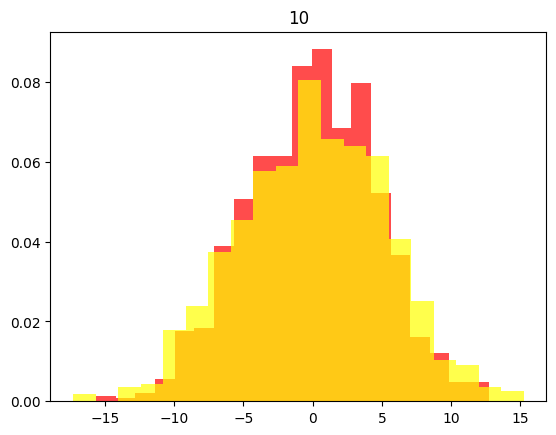

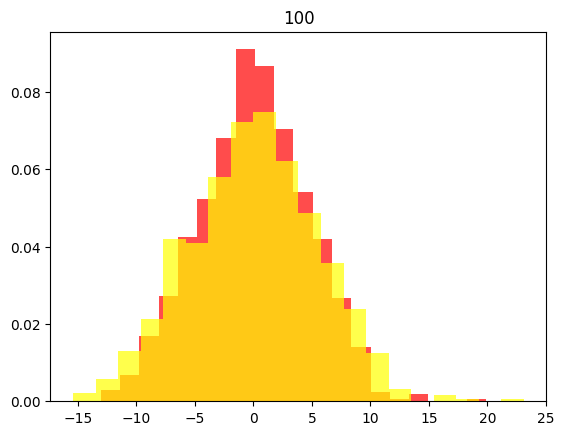

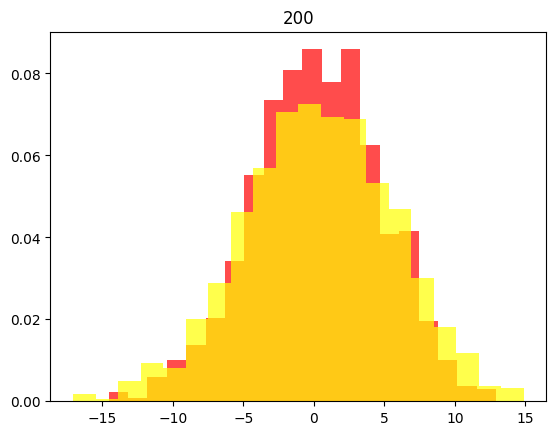

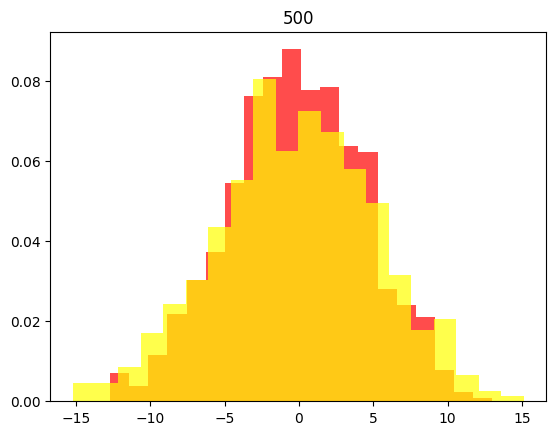

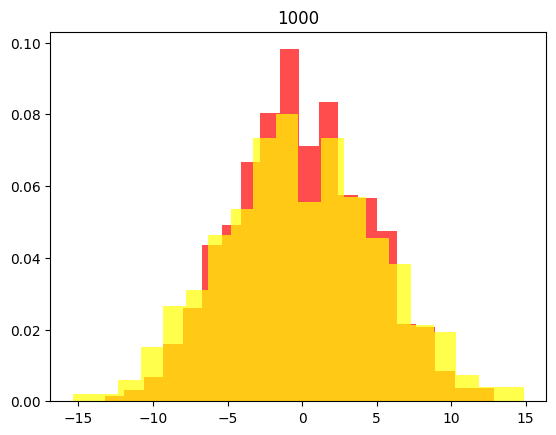

In [6]:
#(c) * Изобразить гистограммы √n(2X − θ) и√n(2Xα − θ) на одном графике, сравнить разбросы
#(обе ли оценки асимптотически нормальны, чья асимптотическая дисперсия меньше?).

a = 0.1
est1 = [0]*m
est2 = [0]*m
for n in numbers:
    for j in range(m):
        x = np.random.uniform(0, tetta, size = n)
        est1[j] = np.sqrt(n)*(2*np.mean(x)-tetta)
        est2[j] = np.sqrt(n)*(2*sc.stats.trim_mean(x, a)-tetta)
    plt.hist(est1, density = True, color = "red", bins = 20, alpha = 0.7)
    plt.hist(est2, density = True, color = "yellow", bins = 20, alpha = 0.7)
    plt.title(n)
    plt.show()

In [16]:
#(d) Сравнить, какая из оценок ((n + 1)/n)X(n) и 2X чаще оказывается ближе к θ при разных n.
#Для этого смоделировать по 1000 реализаций (для каждого n) и найти, в какой доле из этих 1000 ближе оказалась ((n + 1)/n)X(n)

In [7]:
est1 = [0]*m
est2 = [0]*m
for n in numbers:
    count = 0
    for j in range(m):
        x = np.random.uniform(0, tetta, size = n)
        if(np.abs( np.max(x)*(n+1)/n - tetta) < np.abs(2*np.mean(x) - tetta)):
            count+=1
    print(n,count/m)

10 0.728
100 0.911
200 0.938
500 0.955
1000 0.967


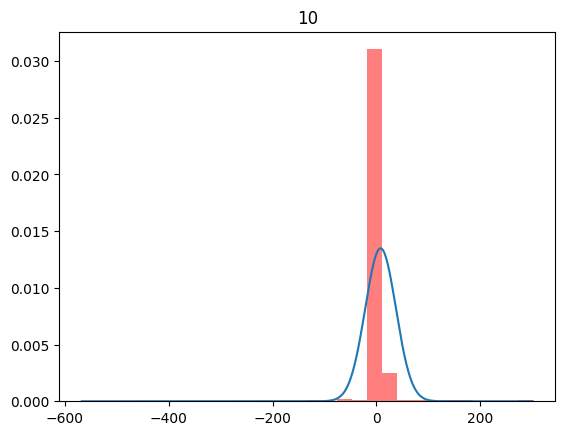

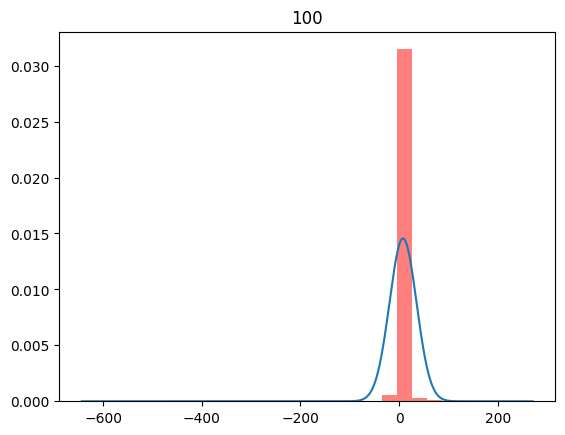

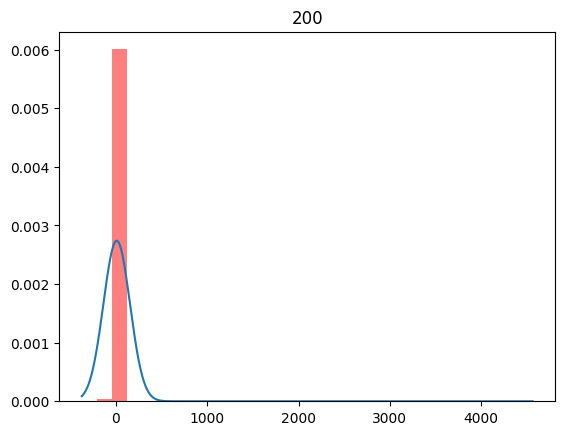

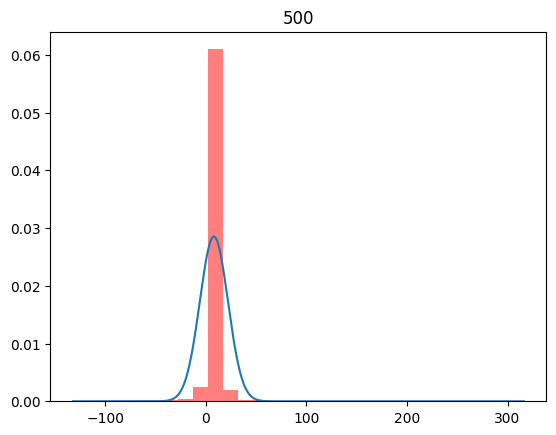

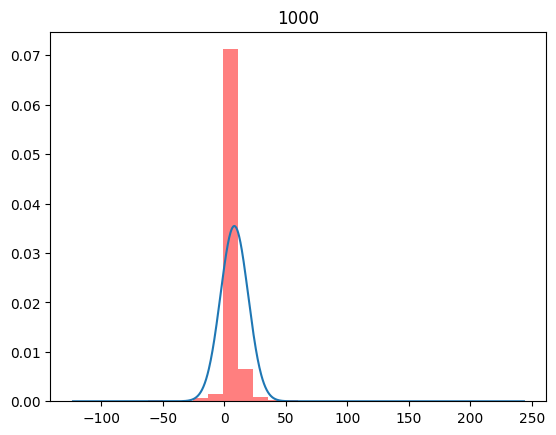

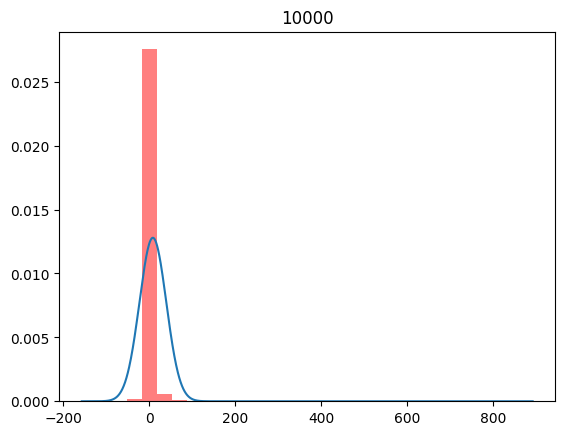

In [14]:
#2. X1, . . . , Xn имеет распределение Коши fθ(x) = (π(1 + (x − θ)2))−1.
#(a) Построить гистограммы для X при разных n. Является ли эта оценка состоятельной?
#*Сравнить гистограмму/оценку плотности с нормальной плотностью.
est1 = [0]*m
est2 = [0]*m
for n in numbers:
    for j in range(m):
        x = np.random.standard_cauchy(size = n) + [tetta]*n
        est1[j] = np.mean(x) 
        sigma = np.var(est1)
    plt.hist(est1, color = "red", density = True, bins = 30, alpha = 0.5)
    a = np.linspace(np.min(est1), np.max(est1), 1000)
    plt.plot(a, sc.stats.norm.pdf(a, loc = tetta, scale = np.sqrt(sigma)))
    plt.title(n)
    plt.show()

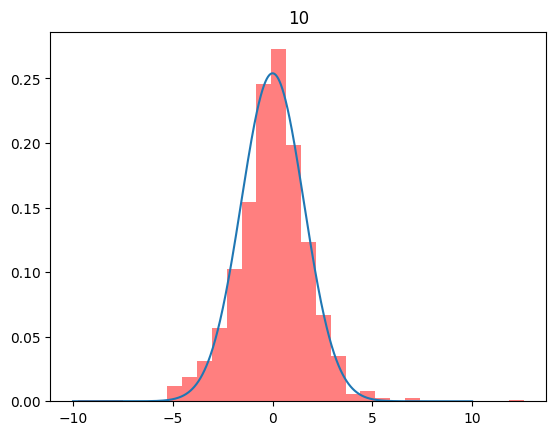

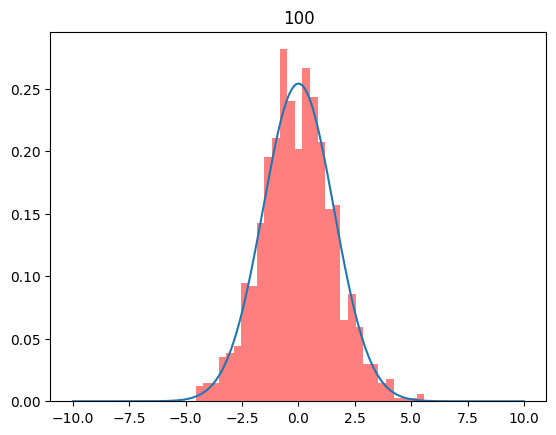

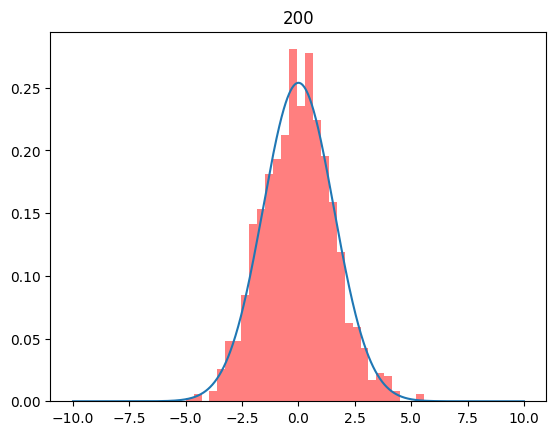

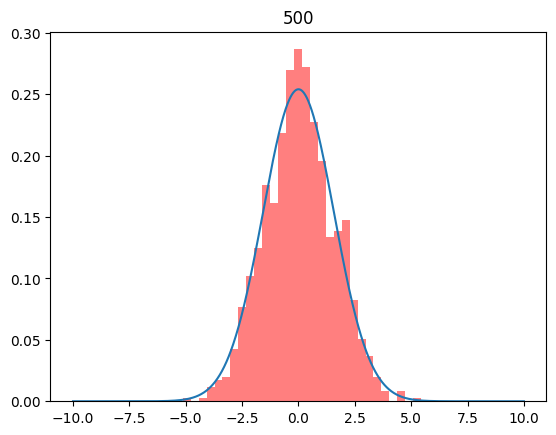

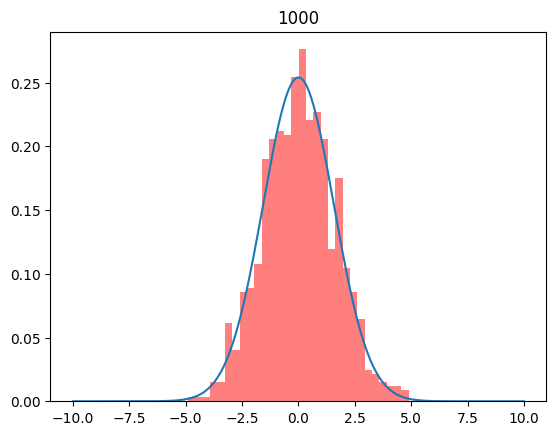

In [8]:
#(b) Построить гистограммы √n(MED −θ), сравнить с соответсвующей нормальной плотностью (см. теорему 1).

est2 = [0]*m
for n in numbers:
    for j in range(m):
        x = np.random.standard_cauchy(size = n) + [tetta]*n
        est2[j] = np.sqrt(n)*(np.median(x) - tetta) 
    plt.hist(est2, color = "red", density = True, bins = 30, alpha = 0.5)
    a = np.linspace(-10, 10, 1000)
    plt.plot(a, sc.stats.norm.pdf(a, loc = 0, scale = np.pi/2))
    plt.title(n)
    plt.show()

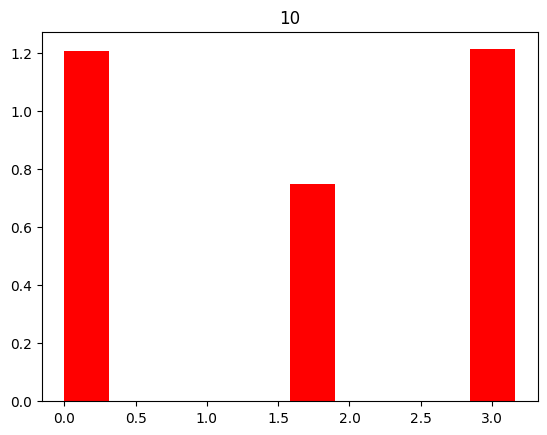

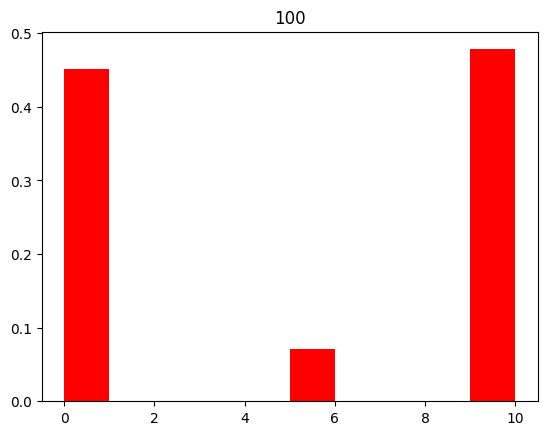

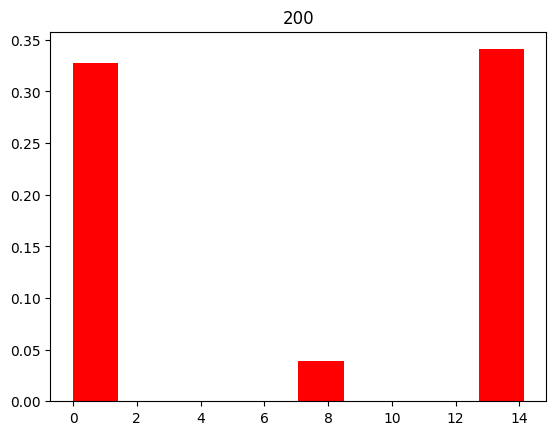

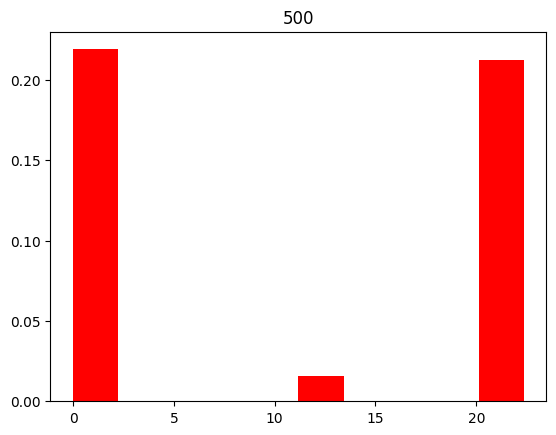

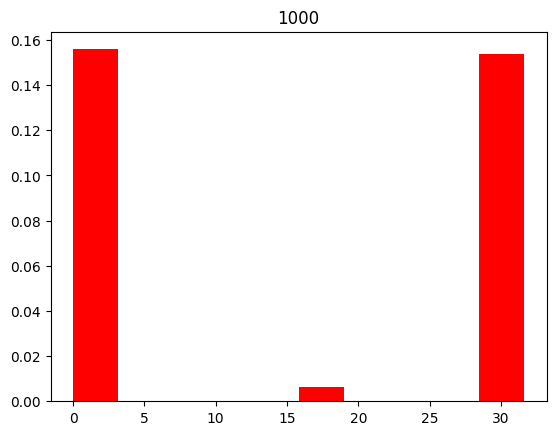

In [5]:
#3. * X1, ..., Xn ∼ Bern(p), где а) p = 1/3 б) p = 1/2. Будет ли MED состоятельна? Асимптотически нормальна?
#Постройте гистограммы √n(MED − x1/2), похоже ли распределение на нормальное?
p = 1/2
for n in numbers:
    for j in range(m):
        x = np.random.binomial(1, p, size = n)
        est[j] = np.sqrt(n)*(np.median(x)) # медиана- оценка квантили уровня 1/2, то есть нуля
    plt.hist(est, density = True, color = "red")
    plt.title(n)
    plt.show()

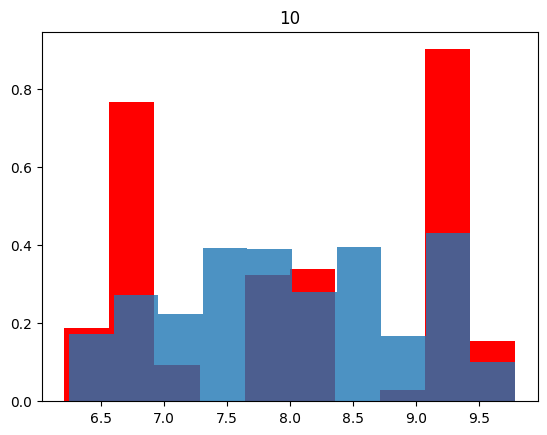

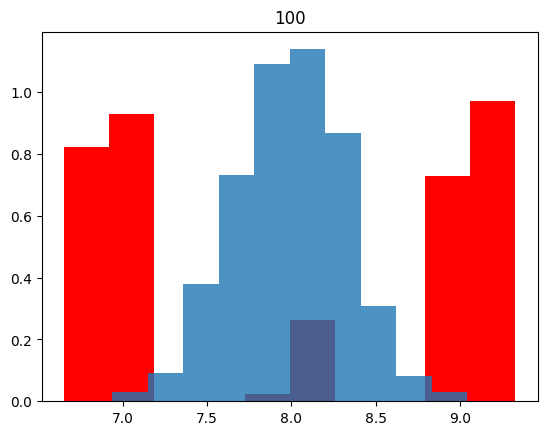

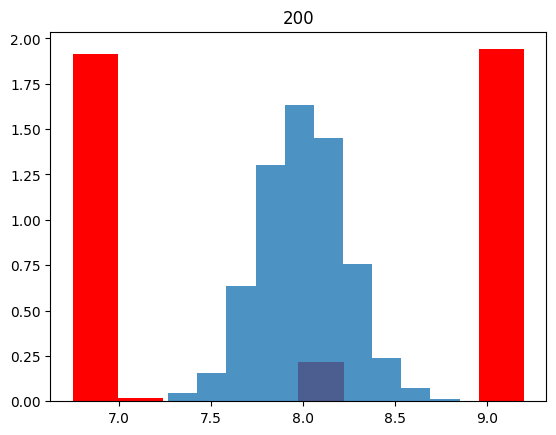

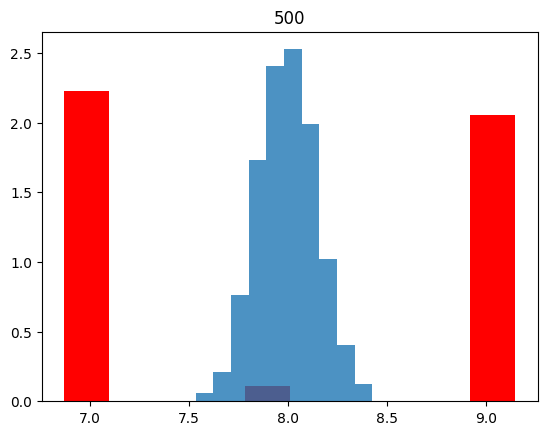

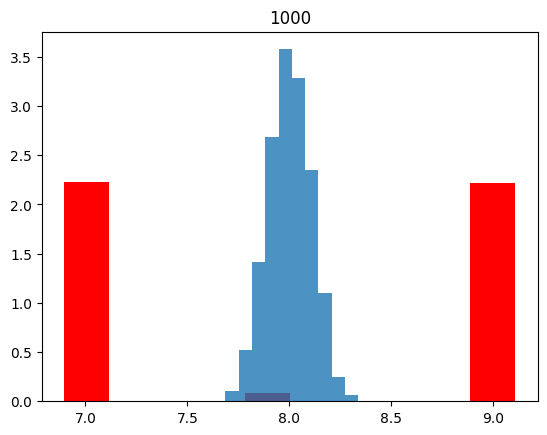

In [73]:
#4. X1, ..., Xn ∼ R([θ − 2, θ − 1] ∪ [θ + 1, θ + 2]). Будут ли выборочная медиана и усеченные средние
#а)состоятельны
def vyborka(n, tetta):
    x = [0]*n
    for j in range(n):
        if np.random.binomial(1,0.5)==0:
            x[j] = np.random.uniform(tetta - 2, tetta - 1)
        else:
             x[j] = np.random.uniform(tetta +1, tetta + 2)
    return x

a=0.3    
for n in numbers:
    for j in range(m):
        x = vyborka(n, tetta)
        est[j] = np.median(x)
        est1[j] = sc.stats.trim_mean(x, a)
    plt.hist(est, color = "red", density = True)
    plt.hist(est1, alpha = 0.8, density = True)
    plt.title(n)
    plt.show()

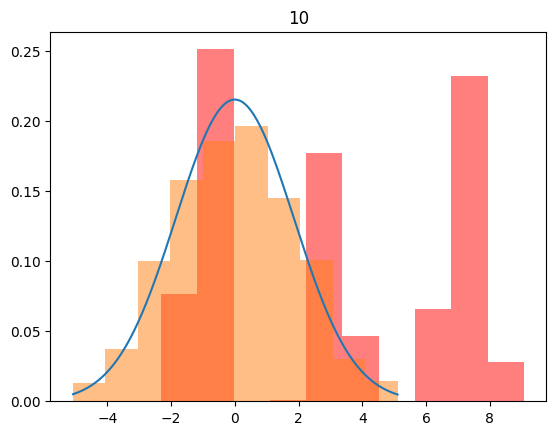

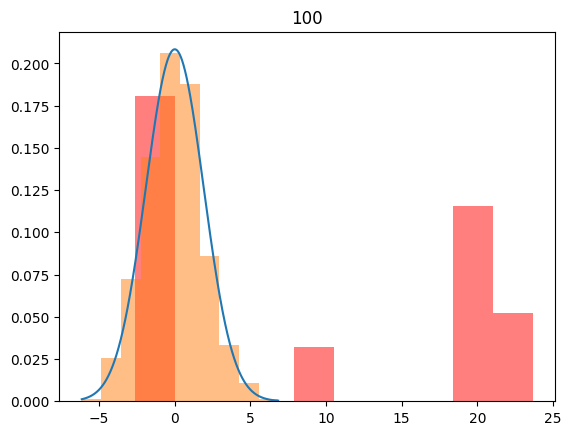

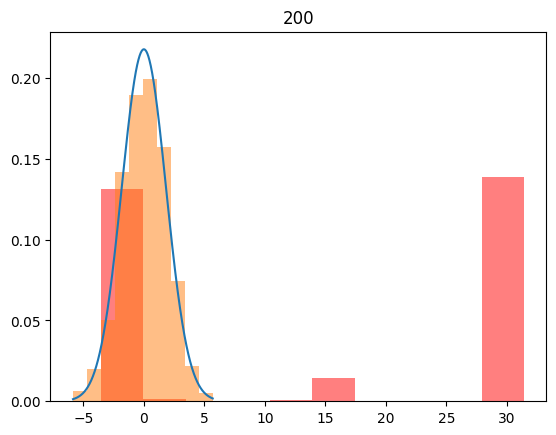

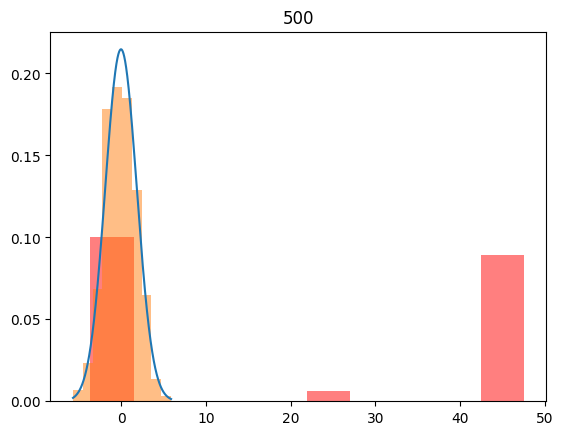

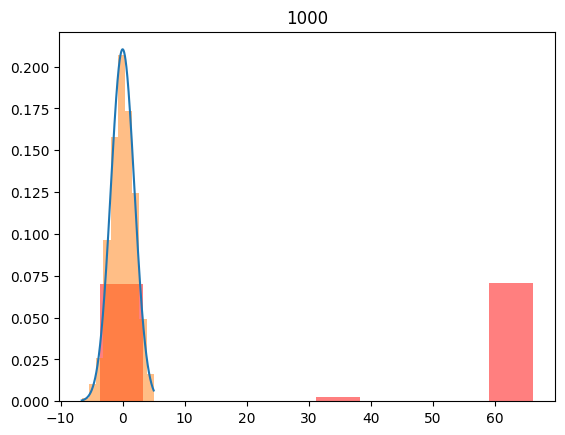

In [72]:
#б) асимптотически нормальны?
for n in numbers:
    for j in range(m):
        x = vyborka(n, tetta)
        est[j] = np.sqrt(n)*( np.median(x)-(tetta-1) )
        est1[j] = np.sqrt(n)*(sc.stats.trim_mean(x, a) - tetta)
    sigma = np.var(est1)
    b = np.linspace(np.min(est1), np.max(est1), 1000)
    plt.plot(b, sc.stats.norm.pdf(b, loc = 0, scale = np.sqrt(sigma)))
    plt.hist(est, color = "red", alpha = 0.5, density = True)
    plt.hist(est1, alpha = 0.5, density = True)
    plt.title(n)
    plt.show()

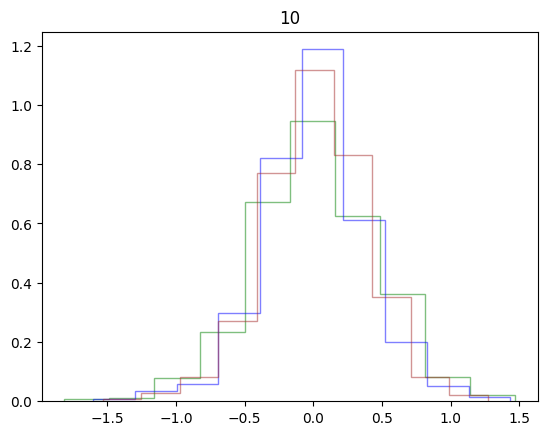

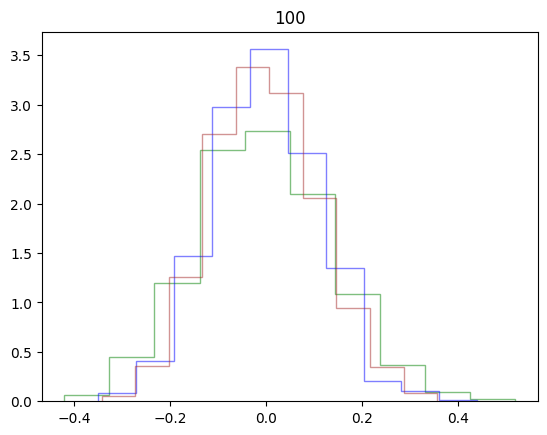

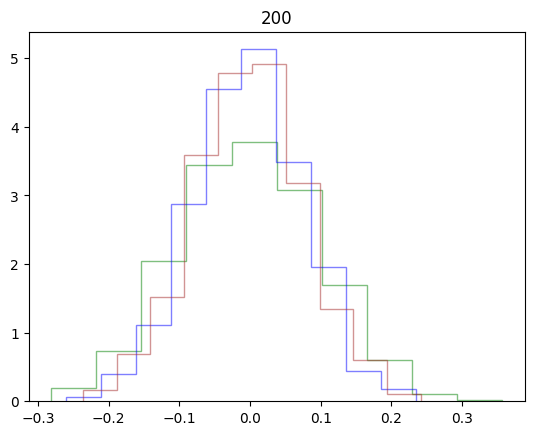

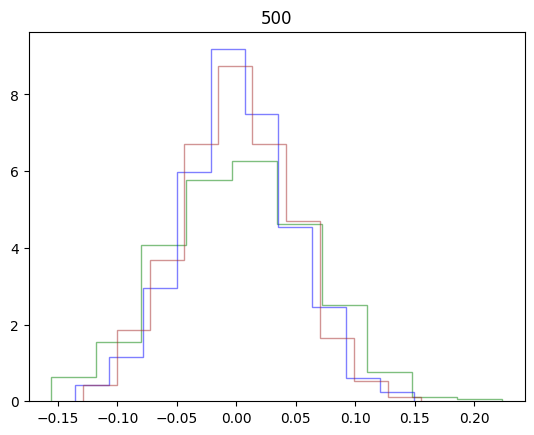

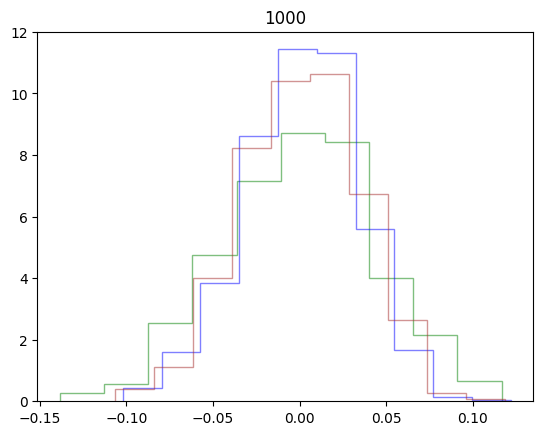

In [12]:
#5. Смоделировать выборку из распределения Лапласа и численно сравнить асимптотическую дис-
#персию медианы, выборочного среднего, Xα с α = 0.1 и α = 0.3. Для этого построить гистограммы или плотности каждого из распределений.
a = 0.3
for n in numbers:
    for j in range(m):
        x = np.random.laplace(size = n)
        est[j] = np.mean(x)
        est1[j] = np.median(x)
        est2[j] = sc.stats.trim_mean(x, a)
    plt.hist(est, color = "green", alpha = 0.5, density = True, histtype = "step") #mean
    plt.hist(est1, color = "blue", alpha = 0.5,  density = True, histtype = "step") #med
    plt.hist(est2, color = "brown", alpha = 0.5,  density = True, histtype = "step") #xa
    plt.title(n)
    plt.show()